# Results Diagnostics Dashboard

This notebook reuses `scripts/plot_results.py` to inspect the saved experiment artifacts without rerunning training.

It complements the baseline ablation report by focusing on:

- what result files are actually available,
- whether coverage is complete across datasets and graph variants,
- how ROC-AUC and average precision rank the methods,
- how far each method is from the best saved baseline,
- what the saved trainable runs suggest about optimization behavior.


In [1]:
from pathlib import Path
import importlib.util

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
RESULTS_DIR = PROJECT_ROOT / "results"
PLOT_RESULTS_PATH = PROJECT_ROOT / "scripts" / "plot_results.py"

spec = importlib.util.spec_from_file_location("plot_results", PLOT_RESULTS_PATH)
if spec is None or spec.loader is None:
    raise RuntimeError(f"Unable to load plotting helpers from {PLOT_RESULTS_PATH}")
plot_results = importlib.util.module_from_spec(spec)
spec.loader.exec_module(plot_results)

pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

PROJECT_ROOT

WindowsPath('.../citegnn')

## 1. Load The Saved Results Through The Shared Plotting Helper

The notebook uses the same filtering and duplicate-handling logic as the CLI plotting script, so the tables below are aligned with the command-line workflow.

In [2]:
records = plot_results.load_result_records(RESULTS_DIR, graph_variant="all")
results_df = pd.DataFrame(records).sort_values(
    ["dataset", "graph_variant", "test_roc_auc"],
    ascending=[True, True, False],
).reset_index(drop=True)

results_df[[
    "dataset",
    "graph_variant",
    "method",
    "seed",
    "test_roc_auc",
    "test_average_precision",
    "relative_path",
]]

,dataset,graph_variant,method,seed,test_roc_auc,test_average_precision,relative_path
0,Cora,undirected,Personalized PageRank,42,0.794227,0.862788,cora\personalized_pagerank_undirected_seed42.json
1,Cora,undirected,Node2Vec,42,0.732836,0.770419,cora\node2vec_seed42.json
2,Cora,undirected,GCN,42,0.675093,0.700412,cora\gcn_seed42.json
3,Cora,undirected,Common Neighbors,42,0.671689,0.670884,cora\common_neighbors_undirected_seed42.json
4,Cora,undirected,Adamic-Adar,42,0.671638,0.670531,cora\adamic_adar_undirected_seed42.json
5,Cora,undirected,GraphSAGE,42,0.523026,0.526227,cora\graphsage_seed42.json
6,PubMed,undirected,GCN,42,0.867818,0.838973,pubmed\gcn_seed42.json
7,PubMed,undirected,Personalized PageRank,42,0.814063,0.873272,pubmed\personalized_pagerank_undirected_seed42.json
8,PubMed,undirected,Adamic-Adar,42,0.612076,0.612357,pubmed\adamic_adar_undirected_seed42.json
9,PubMed,undirected,Common Neighbors,42,0.612039,0.611797,pubmed\common_neighbors_undirected_seed42.json


## 2. Audit Coverage

This section answers a practical project question: which dataset and graph-variant slices do we actually have results for, and which methods are present in each slice?

In [3]:
coverage_summary = (
    results_df.groupby(["dataset", "graph_variant"])
    .agg(
        methods=("method", "nunique"),
        seeds=("seed", "nunique"),
        saved_runs=("method", "size"),
    )
    .reset_index()
)
coverage_summary

,dataset,graph_variant,methods,seeds,saved_runs
0,Cora,undirected,6,1,6
1,PubMed,undirected,6,1,6


In [4]:
coverage_matrix = (
    results_df.assign(present=1)
    .pivot_table(
        index=["dataset", "graph_variant"],
        columns="method",
        values="present",
        aggfunc="max",
        fill_value=0,
    )
    .astype(int)
)
coverage_matrix

,method,Adamic-Adar,Common Neighbors,GCN,GraphSAGE,Node2Vec,Personalized PageRank
dataset,graph_variant,,,,,,
Cora,undirected,1,1,1,1,1,1
PubMed,undirected,1,1,1,1,1,1


## 3. Compare The Saved Undirected Results Across Both Metrics

The existing ablation report already shows saved undirected results. Here the goal is to reuse the shared plotting helper and put ROC-AUC and average precision side by side in one place.

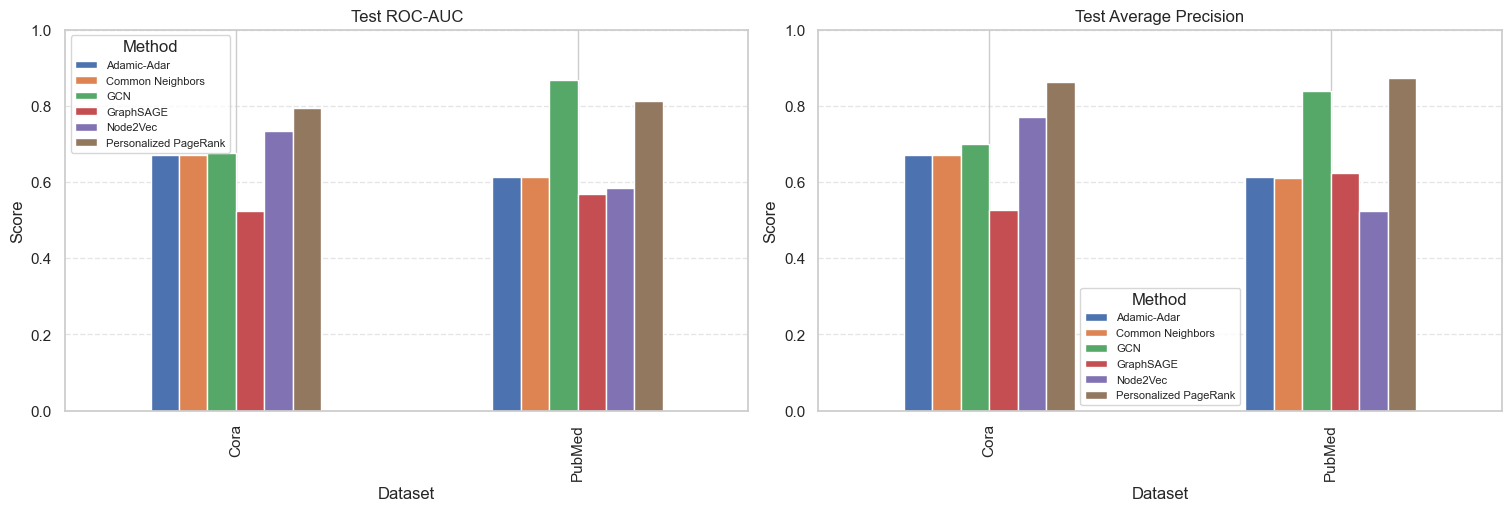

In [5]:
roc_table = plot_results.load_results(RESULTS_DIR, graph_variant="undirected", metric="roc_auc")
ap_table = plot_results.load_results(RESULTS_DIR, graph_variant="undirected", metric="average_precision")

roc_df = pd.DataFrame.from_dict(roc_table, orient="index").sort_index(axis=0).sort_index(axis=1)
ap_df = pd.DataFrame.from_dict(ap_table, orient="index").sort_index(axis=0).sort_index(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
roc_df.plot(kind="bar", ax=axes[0], ylim=(0.0, 1.0), title="Test ROC-AUC")
ap_df.plot(kind="bar", ax=axes[1], ylim=(0.0, 1.0), title="Test Average Precision")

for axis in axes:
    axis.set_xlabel("Dataset")
    axis.set_ylabel("Score")
    axis.grid(axis="y", linestyle="--", alpha=0.5)
    axis.legend(title="Method", fontsize=8)

plt.show()

## 4. Rank The Methods And Measure The Gap To The Best

Absolute scores are useful, but the gap to the best saved method is often easier to talk about in a presentation or discussion section.

In [6]:
undirected_df = results_df.loc[results_df["graph_variant"] == "undirected"].copy()
undirected_df["roc_auc_rank"] = (
    undirected_df.groupby("dataset")["test_roc_auc"].rank(ascending=False, method="dense").astype(int)
)
undirected_df["average_precision_rank"] = (
    undirected_df.groupby("dataset")["test_average_precision"]
    .rank(ascending=False, method="dense")
    .astype(int)
)
undirected_df["roc_auc_gap_to_best"] = (
    undirected_df.groupby("dataset")["test_roc_auc"].transform("max") - undirected_df["test_roc_auc"]
)
undirected_df["average_precision_gap_to_best"] = (
    undirected_df.groupby("dataset")["test_average_precision"].transform("max")
    - undirected_df["test_average_precision"]
)

ranking_table = undirected_df[[
    "dataset",
    "method",
    "test_roc_auc",
    "test_average_precision",
    "roc_auc_rank",
    "average_precision_rank",
    "roc_auc_gap_to_best",
    "average_precision_gap_to_best",
]].sort_values(["dataset", "roc_auc_rank", "average_precision_rank"]).reset_index(drop=True)

ranking_table

,dataset,method,test_roc_auc,test_average_precision,roc_auc_rank,average_precision_rank,roc_auc_gap_to_best,average_precision_gap_to_best
0,Cora,Personalized PageRank,0.794227,0.862788,1,1,0.000000,0.000000
1,Cora,Node2Vec,0.732836,0.770419,2,2,0.061390,0.092368
2,Cora,GCN,0.675093,0.700412,3,3,0.119133,0.162376
3,Cora,Common Neighbors,0.671689,0.670884,4,4,0.122537,0.191904
4,Cora,Adamic-Adar,0.671638,0.670531,5,5,0.122588,0.192257
5,Cora,GraphSAGE,0.523026,0.526227,6,6,0.271201,0.336561
6,PubMed,GCN,0.867818,0.838973,1,2,0.000000,0.034299
7,PubMed,Personalized PageRank,0.814063,0.873272,2,1,0.053755,0.000000
8,PubMed,Adamic-Adar,0.612076,0.612357,3,4,0.255743,0.260915
9,PubMed,Common Neighbors,0.612039,0.611797,4,5,0.255780,0.261475


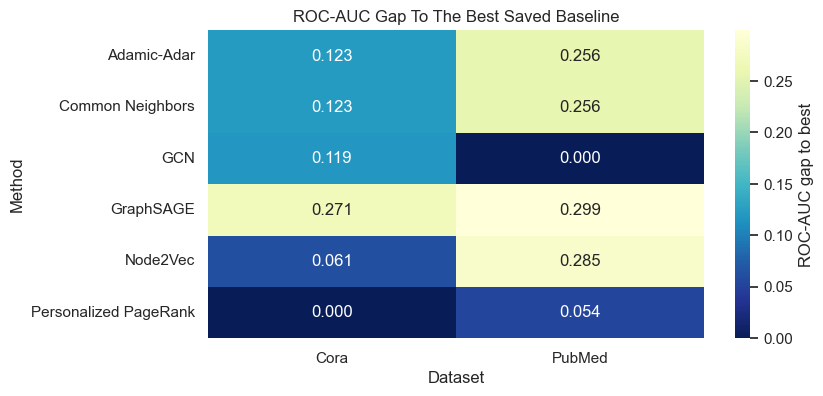

In [7]:
gap_matrix = (
    undirected_df.pivot(index="method", columns="dataset", values="roc_auc_gap_to_best")
    .sort_index(axis=0)
    .sort_index(axis=1)
)

plt.figure(figsize=(8, 4))
sns.heatmap(
    gap_matrix,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu_r",
    cbar_kws={"label": "ROC-AUC gap to best"},
)
plt.title("ROC-AUC Gap To The Best Saved Baseline")
plt.xlabel("Dataset")
plt.ylabel("Method")
plt.show()

## 5. Inspect The Trainable Baselines

For `GCN`, `GraphSAGE`, and `Node2Vec`, the saved JSON files also carry configuration details. This table helps connect the final score to the actual training setup.

In [8]:
trainable_methods = {"GCN", "GraphSAGE", "Node2Vec"}
trainable_df = undirected_df.loc[undirected_df["method"].isin(trainable_methods)].copy()
trainable_df["epochs"] = trainable_df["params"].map(lambda params: params.get("epochs"))
trainable_df["best_epoch"] = trainable_df["params"].map(lambda params: params.get("best_epoch"))
trainable_df["embedding_or_hidden_dim"] = trainable_df["params"].map(
    lambda params: params.get("embedding_dim", params.get("hidden_dim"))
)
trainable_df["early_stop_fraction"] = trainable_df.apply(
    lambda row: (
        row["best_epoch"] / row["epochs"]
        if pd.notna(row["best_epoch"]) and pd.notna(row["epochs"]) and row["epochs"]
        else pd.NA
    ),
    axis=1,
)

trainable_df[[
    "dataset",
    "method",
    "test_roc_auc",
    "test_average_precision",
    "embedding_or_hidden_dim",
    "epochs",
    "best_epoch",
    "early_stop_fraction",
    "relative_path",
]].sort_values(["dataset", "test_roc_auc"], ascending=[True, False]).reset_index(drop=True)

,dataset,method,test_roc_auc,test_average_precision,embedding_or_hidden_dim,epochs,best_epoch,early_stop_fraction,relative_path
0,Cora,Node2Vec,0.732836,0.770419,16,1,NaN,<NA>,cora\node2vec_seed42.json
1,Cora,GCN,0.675093,0.700412,32,5,5.0,1.0,cora\gcn_seed42.json
2,Cora,GraphSAGE,0.523026,0.526227,32,5,5.0,1.0,cora\graphsage_seed42.json
3,PubMed,GCN,0.867818,0.838973,32,5,5.0,1.0,pubmed\gcn_seed42.json
4,PubMed,Node2Vec,0.583225,0.525235,64,3,NaN,<NA>,pubmed\node2vec_undirected_seed42.json
5,PubMed,GraphSAGE,0.568462,0.623854,32,5,2.0,0.4,pubmed\graphsage_seed42.json


## 6. Export A Reusable Figure Through The Shared CLI Helper

This final cell uses `plot_results.py` directly to save a ready-to-share comparison figure, which is useful for reports or presentation slides.

In [9]:
figure_output = PROJECT_ROOT / "results" / "notebook_model_comparison_roc_auc.png"
plot_results.plot_grouped_bar_chart(
    roc_table,
    figure_output,
    metric="roc_auc",
    graph_variant="undirected",
)
figure_output.relative_to(PROJECT_ROOT)

Plot successfully saved to: ...\citegnn\results\notebook_model_comparison_roc_auc.png


WindowsPath('results/notebook_model_comparison_roc_auc.png')